In [3]:
import pandas as pd
test = pd.read_csv("data_mobil_bekas.csv")
test.head()

,brand,model,model_year,mileage,fuel_type,engine,transmission,ext_col,int_col,accident,clean_title,price
0,Ford,Utility Police Interceptor Base,2013.0,51000.0,E85 Flex Fuel,300.0HP 3.7L V6 Cylinder Engine Flex Fuel Capa...,6-Speed A/T,Black,Black,At least 1 accident or damage reported,Yes,10300.0
1,Hyundai,Palisade SEL,2021.0,34742.0,Gasoline,3.8L V6 24V GDI DOHC,8-Speed Automatic,Moonlight Cloud,Gray,At least 1 accident or damage reported,Yes,38005.0
2,Lexus,RX 350 RX 350,2022.0,22372.0,Gasoline,3.5 Liter DOHC,Automatic,Blue,Black,None reported,NaN,54598.0
3,INFINITI,Q50 Hybrid Sport,2015.0,88900.0,Hybrid,354.0HP 3.5L V6 Cylinder Engine Gas/Electric H...,7-Speed A/T,Black,Black,None reported,Yes,15500.0
4,Audi,Q3 45 S line Premium Plus,2021.0,9835.0,Gasoline,2.0L I4 16V GDI DOHC Turbo,8-Speed Automatic,Glacier White Metallic,Black,None reported,NaN,34999.0


In [4]:
train = pd.read_csv("data_mobil_bekas.csv")
train.head()

,brand,model,model_year,mileage,fuel_type,engine,transmission,ext_col,int_col,accident,clean_title,price
0,Ford,Utility Police Interceptor Base,2013.0,51000.0,E85 Flex Fuel,300.0HP 3.7L V6 Cylinder Engine Flex Fuel Capa...,6-Speed A/T,Black,Black,At least 1 accident or damage reported,Yes,10300.0
1,Hyundai,Palisade SEL,2021.0,34742.0,Gasoline,3.8L V6 24V GDI DOHC,8-Speed Automatic,Moonlight Cloud,Gray,At least 1 accident or damage reported,Yes,38005.0
2,Lexus,RX 350 RX 350,2022.0,22372.0,Gasoline,3.5 Liter DOHC,Automatic,Blue,Black,None reported,NaN,54598.0
3,INFINITI,Q50 Hybrid Sport,2015.0,88900.0,Hybrid,354.0HP 3.5L V6 Cylinder Engine Gas/Electric H...,7-Speed A/T,Black,Black,None reported,Yes,15500.0
4,Audi,Q3 45 S line Premium Plus,2021.0,9835.0,Gasoline,2.0L I4 16V GDI DOHC Turbo,8-Speed Automatic,Glacier White Metallic,Black,None reported,NaN,34999.0


In [5]:
# Menampilkan ringkasan informasi dari dataset
train.info()

<class 'pandas.DataFrame'>
RangeIndex: 4009 entries, 0 to 4008
Data columns (total 12 columns):
 #   Column        Non-Null Count  Dtype  
---  ------        --------------  -----  
 0   brand         4009 non-null   str    
 1   model         3975 non-null   str    
 2   model_year    3975 non-null   float64
 3   mileage       3975 non-null   float64
 4   fuel_type     3805 non-null   str    
 5   engine        3975 non-null   str    
 6   transmission  3975 non-null   str    
 7   ext_col       3975 non-null   str    
 8   int_col       3975 non-null   str    
 9   accident      3862 non-null   str    
 10  clean_title   3413 non-null   str    
 11  price         3975 non-null   float64
dtypes: float64(3), str(9)
memory usage: 376.0 KB


In [6]:
# Menampilkan statistik deskriptif dari dataset
train.describe(include="all")

,brand,model,model_year,mileage,fuel_type,engine,transmission,ext_col,int_col,accident,clean_title,price
count,4009,3975,3975.000000,3975.000000,3805,3975,3975,3975,3975,3862,3413,3.975000e+03
unique,91,1883,NaN,NaN,7,1118,52,303,148,2,1,NaN
top,Ford,M3 Base,NaN,NaN,Gasoline,2.0L I4 16V GDI DOHC Turbo,A/T,Black,Black,None reported,Yes,NaN
freq,386,30,NaN,NaN,3275,52,1037,905,2016,2880,3413,NaN
mean,NaN,NaN,2015.476981,65042.597233,NaN,NaN,NaN,NaN,NaN,NaN,NaN,4.388917e+04
std,NaN,NaN,6.112345,52341.882986,NaN,NaN,NaN,NaN,NaN,NaN,NaN,7.794547e+04
min,NaN,NaN,1974.000000,100.000000,NaN,NaN,NaN,NaN,NaN,NaN,NaN,2.000000e+03
25%,NaN,NaN,2012.000000,23212.500000,NaN,NaN,NaN,NaN,NaN,NaN,NaN,1.700000e+04
50%,NaN,NaN,2017.000000,53401.000000,NaN,NaN,NaN,NaN,NaN,NaN,NaN,3.100000e+04
75%,NaN,NaN,2020.000000,94500.000000,NaN,NaN,NaN,NaN,NaN,NaN,NaN,4.988900e+04


In [7]:
# Memeriksa jumlah nilai yang hilang di setiap kolom
missing_values = train.isnull().sum()
missing_values[missing_values > 0]

model            34
model_year       34
mileage          34
fuel_type       204
engine           34
transmission     34
ext_col          34
int_col          34
accident        147
clean_title     596
price            34
dtype: int64

In [8]:
less = missing_values[missing_values < 1000].index
over = missing_values[missing_values >= 1000].index

In [9]:
# Contoh mengisi nilai yang hilang dengan median untuk kolom numerik
numeric_features = train[less].select_dtypes(include=['number']).columns
train[numeric_features] = train[numeric_features].fillna(train[numeric_features].median())

In [33]:
# Contoh mengisi nilai yang hilang dengan mode untuk kolom kategori
kategorical_features = train[less].select_dtypes(include=['str']).columns 
for columns in kategorical_features: 
    train[columns] = train[columns].fillna(train[columns].mode()[0])

In [11]:
# Menghapus kolom dengan terlalu banyak nilai yang hilang
df = train.drop(columns=over)

In [12]:
 missing_values = df.isnull().sum()
 missing_values[missing_values > 0]

Series([], dtype: int64)

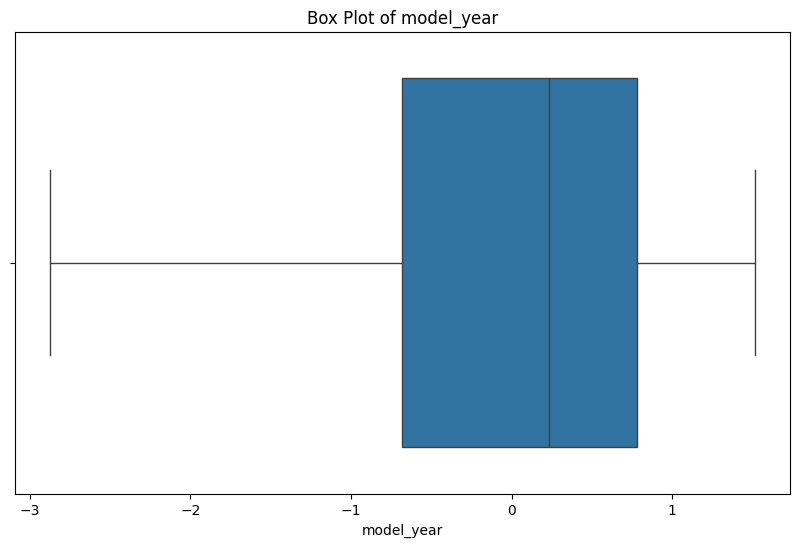

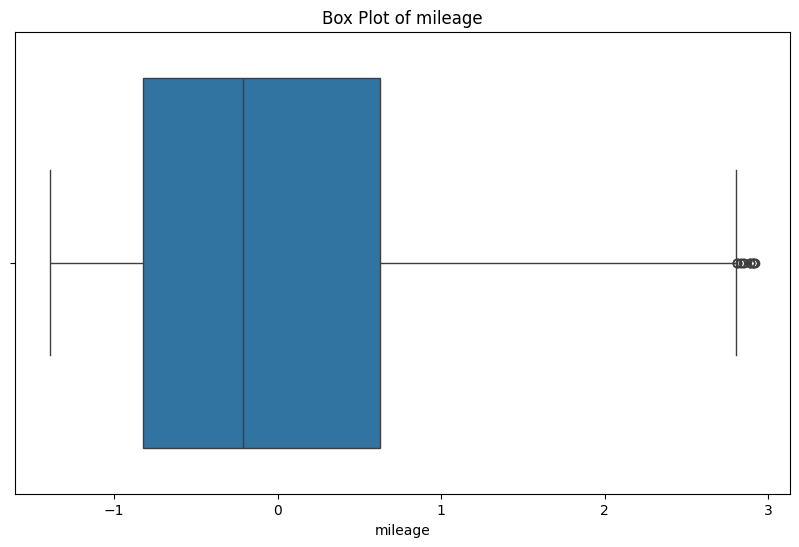

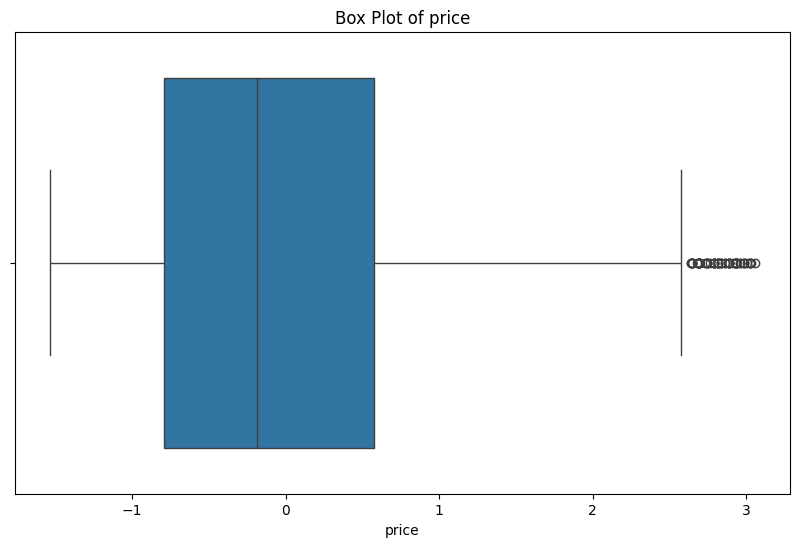

In [22]:
numeric_features = ['model_year', 'mileage', 'price']

for feature in numeric_features:
    plt.figure(figsize=(10, 6))
    sns.boxplot(x=df[feature])
    plt.title(f'Box Plot of {feature}')
    plt.xlabel(feature)
    plt.show()

In [23]:
# Contoh sederhana untuk mengidentifikasi outliers menggunakan IQR
Q1 = df[numeric_features].quantile(0.25)
Q3 = df[numeric_features].quantile(0.75)
IQR = Q3 - Q1

In [24]:
# Filter dataframe untuk hanya menyimpan baris yang tidak mengandung outliers pada kolom numerik
condition = ~((df[numeric_features] < (Q1 - 1.5 * IQR)) | (df[numeric_features] > (Q3 + 1.5 * IQR))).any(axis=1)
df_filtered_numeric = df.loc[condition, numeric_features]
# Menggabungkan kembali dengan kolom kategorikal
categorical_features = df.select_dtypes(include=['str']).columns
df = pd.concat([df_filtered_numeric, df.loc[condition, categorical_features]], axis=1)

In [25]:
from sklearn.preprocessing import StandardScaler
# Standardisasi fitur numerik
scaler = StandardScaler()
df[numeric_features] = scaler.fit_transform(df[numeric_features])

Text(0.5, 1.0, 'Histogram Sebelum Standardisasi')

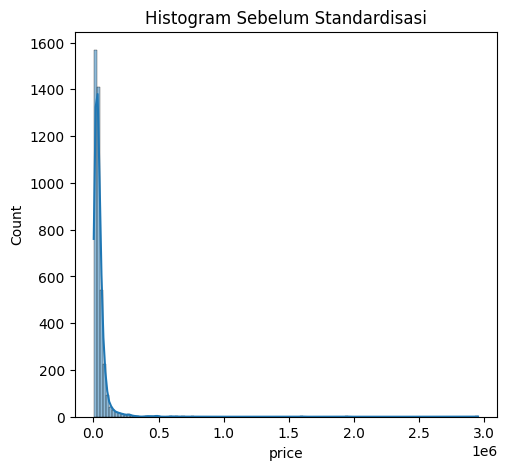

In [40]:

# Histogram Sebelum Standardisasi
plt.figure(figsize=(12, 5))
plt.subplot(1, 2, 1)
sns.histplot(train[numeric_features[2]], kde=True)
plt.title("Histogram Sebelum Standardisasi")

Text(0.5, 1.0, 'Histogram Setelah Standardisasi')

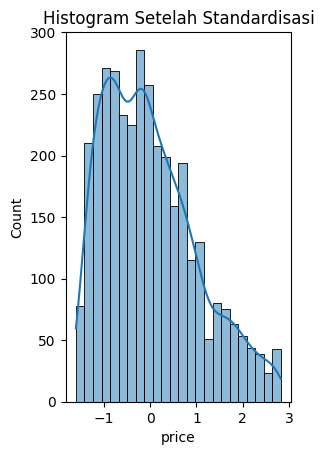

In [42]:
# Histogram Setelah Standardisasi
plt.subplot(1, 2, 2)
sns.histplot(df[numeric_features[2]], kde=True)
plt.title("Histogram Setelah Standardisasi")

In [43]:
# Mengidentifikasi baris duplikat
duplicates = df.duplicated()
print("Baris duplikat:")
print(df[duplicates])

Baris duplikat:
Empty DataFrame
Columns: [model_year, mileage, price, brand, model, fuel_type, engine, transmission, ext_col, int_col, accident, clean_title]
Index: []


In [44]:
# Menghapus baris duplikat
df = df.drop_duplicates()
print("DataFrame setelah menghapus duplikat:")
print(df)

DataFrame setelah menghapus duplikat:
      model_year   mileage     price          brand  \
0      -0.483877 -0.306742 -1.169207           Ford   
1       0.984952 -0.665159  0.262039        Hyundai   
2       1.168555 -0.937863  1.119237          Lexus   
3      -0.116670  0.528785 -0.900574       INFINITI   
4       0.984952 -1.214248  0.106749           Audi   
...          ...       ...       ...            ...   
4001   -0.851084  2.845776 -1.520496     Volkswagen   
4003    0.434141 -0.247109 -0.363308  Mercedes-Benz   
4005    1.168555 -1.190770  1.083178           Audi   
4007    0.801348 -0.703562  1.553234           Ford   
4008    0.801348 -0.483107  0.365101            BMW   

                                model      fuel_type  \
0     Utility Police Interceptor Base  E85 Flex Fuel   
1                        Palisade SEL       Gasoline   
2                       RX 350 RX 350       Gasoline   
3                    Q50 Hybrid Sport         Hybrid   
4           Q3 45 S l

In [45]:
category_features = df.select_dtypes(include=['str']).columns
df[category_features]

,brand,model,fuel_type,engine,transmission,ext_col,int_col,accident,clean_title
0,Ford,Utility Police Interceptor Base,E85 Flex Fuel,300.0HP 3.7L V6 Cylinder Engine Flex Fuel Capa...,6-Speed A/T,Black,Black,At least 1 accident or damage reported,Yes
1,Hyundai,Palisade SEL,Gasoline,3.8L V6 24V GDI DOHC,8-Speed Automatic,Moonlight Cloud,Gray,At least 1 accident or damage reported,Yes
2,Lexus,RX 350 RX 350,Gasoline,3.5 Liter DOHC,Automatic,Blue,Black,None reported,Yes
3,INFINITI,Q50 Hybrid Sport,Hybrid,354.0HP 3.5L V6 Cylinder Engine Gas/Electric H...,7-Speed A/T,Black,Black,None reported,Yes
4,Audi,Q3 45 S line Premium Plus,Gasoline,2.0L I4 16V GDI DOHC Turbo,8-Speed Automatic,Glacier White Metallic,Black,None reported,Yes
...,...,...,...,...,...,...,...,...,...
4001,Volkswagen,Routan SE,Gasoline,283.0HP 3.6L V6 Cylinder Engine Gasoline Fuel,Transmission w/Dual Shift Mode,Black,Gray,At least 1 accident or damage reported,Yes
4003,Mercedes-Benz,E-Class E 300 4MATIC,Gasoline,241.0HP 2.0L 4 Cylinder Engine Gasoline Fuel,A/T,Black,Black,At least 1 accident or damage reported,Yes
4005,Audi,S4 3.0T Premium Plus,Gasoline,349.0HP 3.0L V6 Cylinder Engine Gasoline Fuel,Transmission w/Dual Shift Mode,Black,Black,None reported,Yes
4007,Ford,F-150 Raptor,Gasoline,450.0HP 3.5L V6 Cylinder Engine Gasoline Fuel,A/T,Blue,Black,None reported,Yes


In [47]:
df_one_hot = pd.get_dummies(df, columns = category_features)
df_one_hot

,model_year,mileage,price,brand_Acura,brand_Alfa,"brand_Alfa,Romeo Stelvio Ti Sport,2019,39615,Gasoline,""2L I-4 gasoline direct injection, MultiAir2 variable valve contr"",""Automatic, 8-Spd"",Vulcano Black Metallic,Red/Black,None reported,,28900",brand_Aston,brand_Audi,"brand_Audi,A6 55 Premium Plus,2023,6581,Gasoline,""3L V-6 gasoline direct injection, DOHC, variable valve control,"",""Automatic, 7-Spd S tronic Dual-Clutch"",Chronos Gray Metallic,Black,None reported,,59900",brand_BMW,...,int_col_Very Light Cashmere,int_col_Walnut,int_col_Whisper Beige,int_col_White,int_col_White / Brown,int_col_Yellow,int_col_–,accident_At least 1 accident or damage reported,accident_None reported,clean_title_Yes
0,-0.483877,-0.306742,-1.169207,False,False,False,False,False,False,False,...,False,False,False,False,False,False,False,True,False,True
1,0.984952,-0.665159,0.262039,False,False,False,False,False,False,False,...,False,False,False,False,False,False,False,True,False,True
2,1.168555,-0.937863,1.119237,False,False,False,False,False,False,False,...,False,False,False,False,False,False,False,False,True,True
3,-0.116670,0.528785,-0.900574,False,False,False,False,False,False,False,...,False,False,False,False,False,False,False,False,True,True
4,0.984952,-1.214248,0.106749,False,False,False,False,True,False,False,...,False,False,False,False,False,False,False,False,True,True
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
4001,-0.851084,2.845776,-1.520496,False,False,False,False,False,False,False,...,False,False,False,False,False,False,False,True,False,True
4003,0.434141,-0.247109,-0.363308,False,False,False,False,False,False,False,...,False,False,False,False,False,False,False,True,False,True
4005,1.168555,-1.190770,1.083178,False,False,False,False,True,False,False,...,False,False,False,False,False,False,False,False,True,True
4007,0.801348,-0.703562,1.553234,False,False,False,False,False,False,False,...,False,False,False,False,False,False,False,False,True,True


In [48]:
from sklearn.preprocessing import LabelEncoder 
# Inisialisasi LabelEncoder
label_encoder = LabelEncoder()
df_lencoder = pd.DataFrame(df)
for col in category_features:
    df_lencoder[col] = label_encoder.fit_transform(df[col])
# Menampilkan hasil
df_lencoder

,model_year,mileage,price,brand,model,fuel_type,engine,transmission,ext_col,int_col,accident,clean_title
0,-0.483877,-0.306742,-1.169207,19,1550,1,531,14,17,8,0,0
1,0.984952,-0.665159,0.262039,24,1044,2,519,26,143,54,0,0
2,1.168555,-0.937863,1.119237,45,1168,2,498,32,25,8,1,0
3,-0.116670,0.528785,-0.900574,25,1098,3,667,20,17,8,1,0
4,0.984952,-1.214248,0.106749,4,1081,2,188,26,88,8,1,0
...,...,...,...,...,...,...,...,...,...,...,...,...
4001,-0.851084,2.845776,-1.520496,84,1212,2,436,40,17,54,0,0
4003,0.434141,-0.247109,-0.363308,55,471,2,316,31,17,8,0,0
4005,1.168555,-1.190770,1.083178,4,1286,2,657,40,17,8,1,0
4007,0.801348,-0.703562,1.553234,19,579,2,842,31,25,8,1,0


In [49]:
df_lencoder.head()

,model_year,mileage,price,brand,model,fuel_type,engine,transmission,ext_col,int_col,accident,clean_title
0,-0.483877,-0.306742,-1.169207,19,1550,1,531,14,17,8,0,0
1,0.984952,-0.665159,0.262039,24,1044,2,519,26,143,54,0,0
2,1.168555,-0.937863,1.119237,45,1168,2,498,32,25,8,1,0
3,-0.116670,0.528785,-0.900574,25,1098,3,667,20,17,8,1,0
4,0.984952,-1.214248,0.106749,4,1081,2,188,26,88,8,1,0


In [50]:
missing_values = df_lencoder.isnull().sum()
missing_percentage = (missing_values / len(df_lencoder)) *100

missing_data = pd.DataFrame({
    'Missing Values': missing_values,
    'Percentage': missing_percentage
}).sort_values(by='Missing Values', ascending=False)

missing_data[missing_data['Missing Values'] > 0]

,Missing Values,Percentage


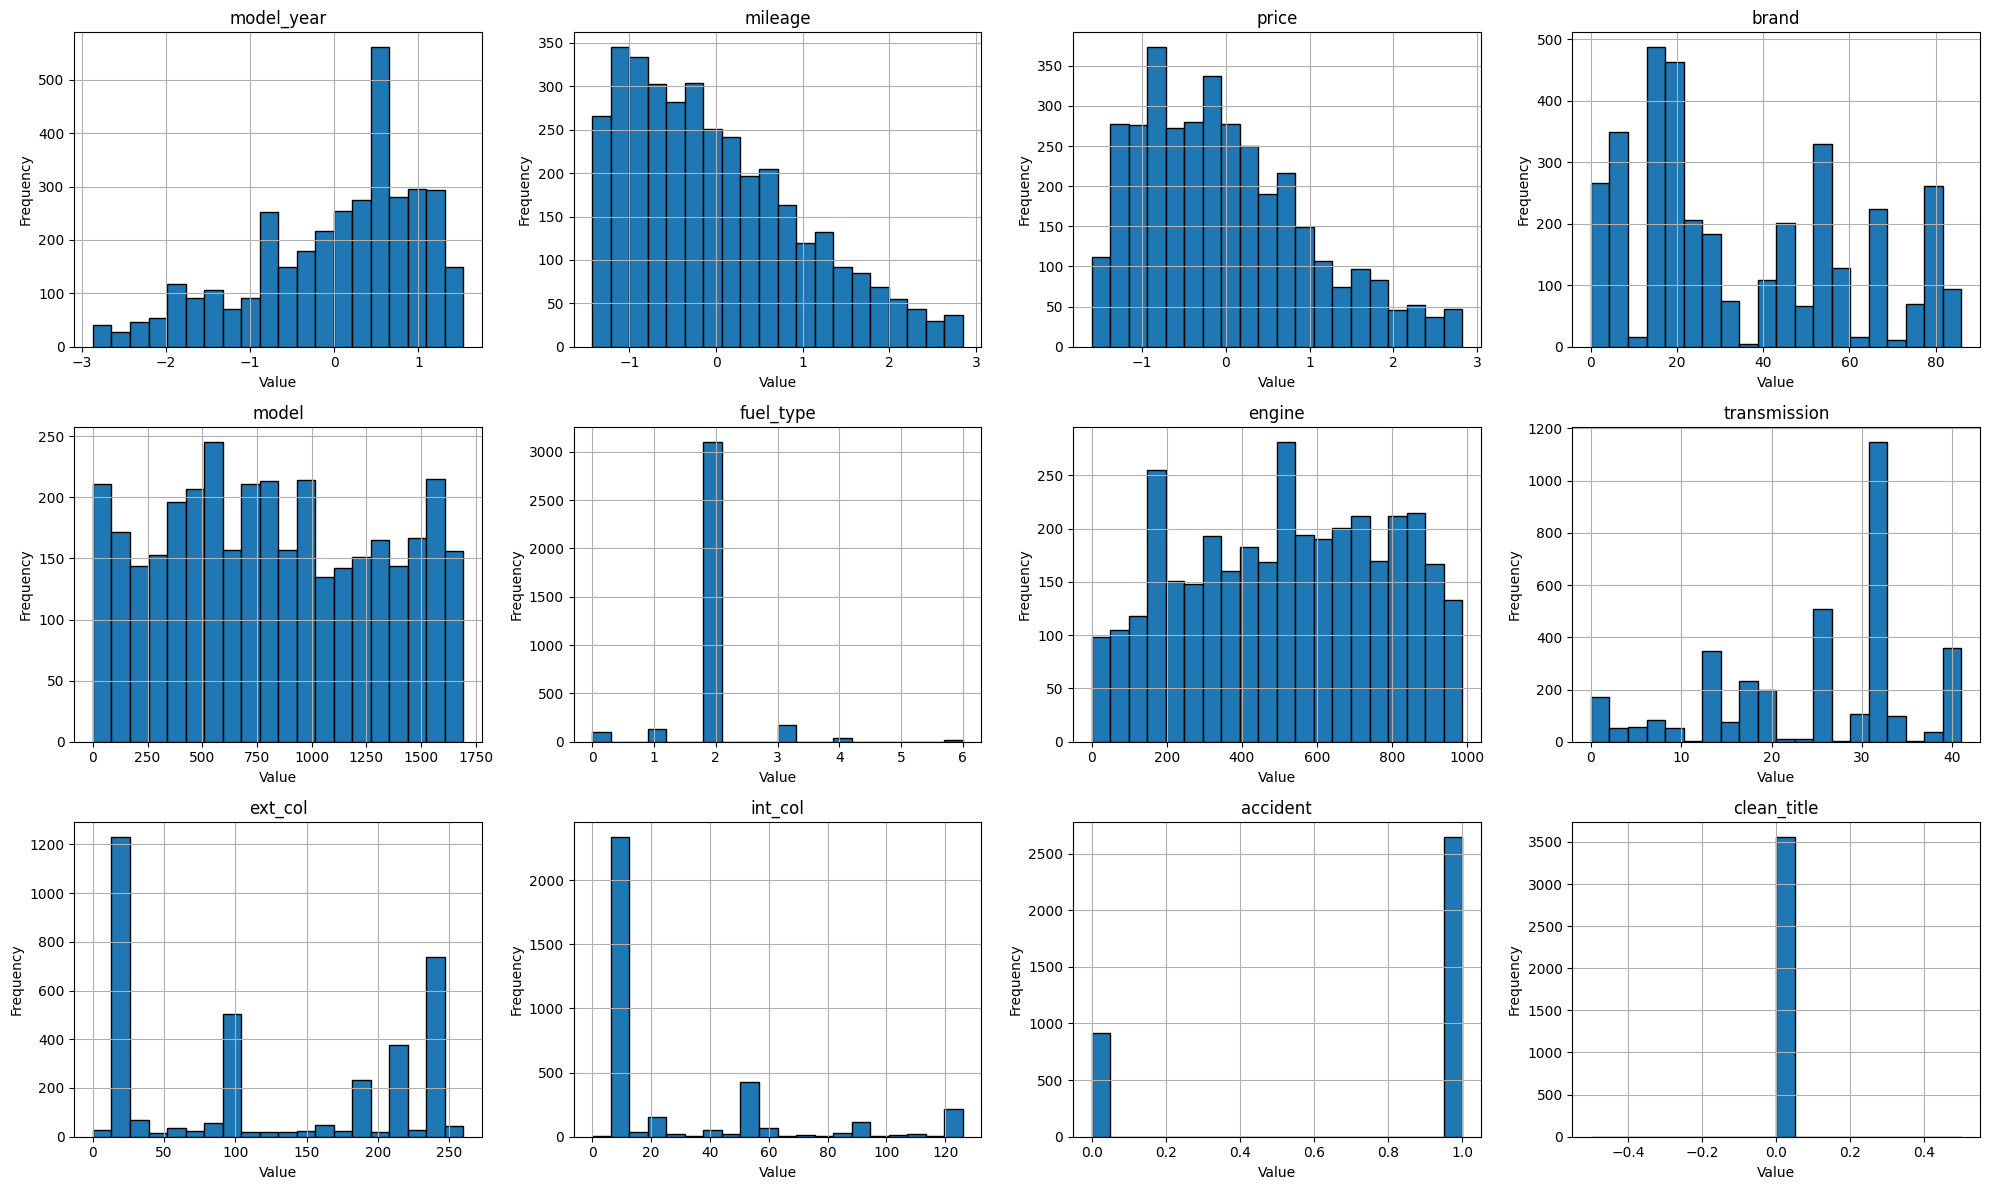

In [51]:
# Menghitung jumlah variabel
num_vars = df_lencoder.shape[1]

# Menentukan jumlah baris dan kolom untuk grid subplot
n_cols = 4 # Jumlah kolom yang diinginkan
n_rows = -(-num_vars // n_cols) # Ceiling division untuk menentukan jumlah baris

# Membuat subplot
fig, axes = plt.subplots(n_rows, n_cols, figsize=(20, n_rows * 4))

# Flatten axes array untuk memudahkan iterasi jika diperlukan
axes = axes.flatten()

# Plot setiap variabel
for i, column in enumerate(df_lencoder.columns):
    df_lencoder[column].hist(ax=axes[i], bins=20, edgecolor='black')
    axes[i].set_title(column)
    axes[i].set_xlabel('Value')
    axes[i].set_ylabel('Frequency')
    
# Menghapus subplot yang tidak terpakai (jika ada)
for j in range(i + 1, len(axes)):
    fig.delaxes(axes[j])
    
# Menyesuaikan layout agar lebih rapi
plt.tight_layout()
plt.show()

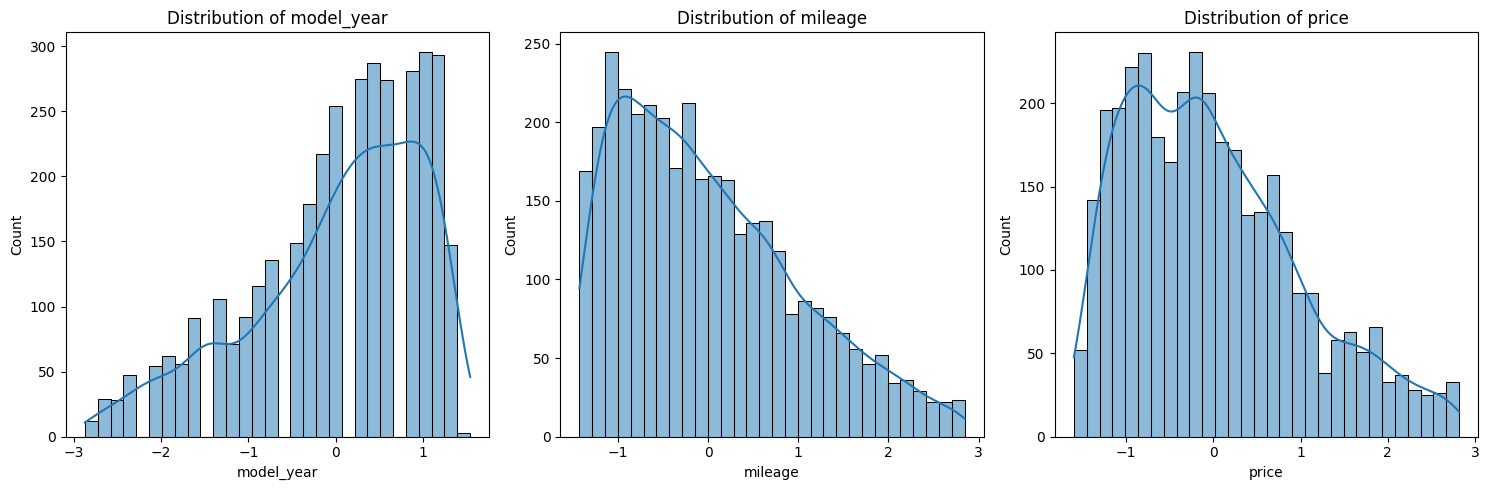

In [53]:
import matplotlib.pyplot as plt
import seaborn as sns

columns_to_plot = [
    'model_year',
    'mileage',
    'price'
]

plt.figure(figsize=(15, 5))

for i, column in enumerate(columns_to_plot, 1):
    plt.subplot(1, 3, i)
    sns.histplot(df_lencoder[column], kde=True, bins=30)
    plt.title(f'Distribution of {column}')
    plt.xlabel(column)

plt.tight_layout()
plt.show()

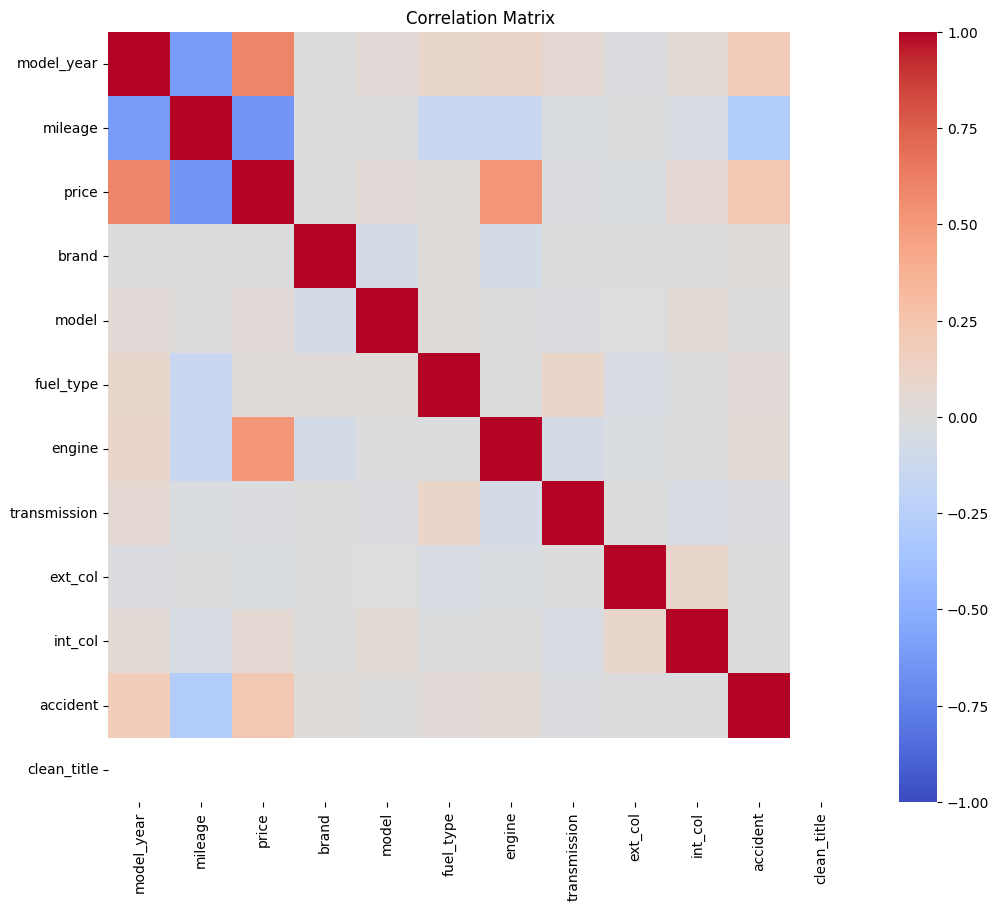

In [54]:
# Visualisasi korelasi antar variabel numerik
plt.figure(figsize=(12, 10))
correlation_matrix = df_lencoder.corr()

sns.heatmap(correlation_matrix, annot=False, cmap='coolwarm', vmin=-1, vmax=1)
plt.title('Correlation Matrix')
plt.show()

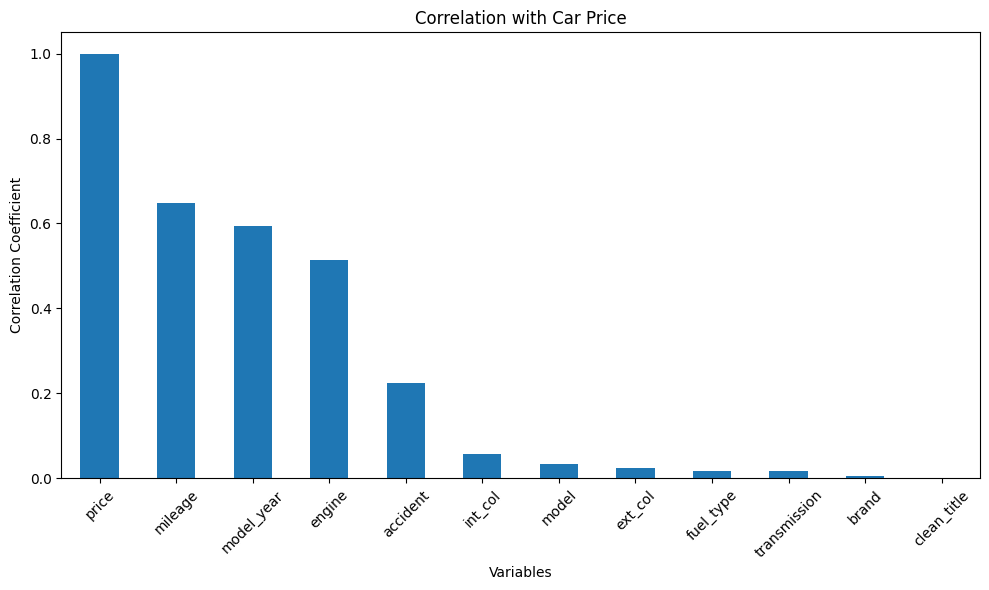

In [56]:
# Menghitung korelasi antara variabel target (price)
# dan variabel numerik lainnya

target_corr = df_lencoder.corr(numeric_only=True)['price']

# Mengurutkan berdasarkan nilai korelasi absolut
target_corr_sorted = target_corr.abs().sort_values(ascending=False)

plt.figure(figsize=(10, 6))
target_corr_sorted.plot(kind='bar')

plt.title('Correlation with Car Price')
plt.xlabel('Variables')
plt.ylabel('Correlation Coefficient')

plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

In [57]:
import sklearn

In [58]:
# Memisahkan fitur (X) dan target (y)
X = df_lencoder.drop(columns=['price'])
y = df_lencoder['price'] 

In [59]:
from sklearn.model_selection import train_test_split

# membagi dataset menjadi training dan testing 
x_train, x_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=1)

In [60]:
# menghitung panjang/jumlah data 
print("Jumlah data: ",len(X))
# menghitung panjang/jumlah data pada x_train
print("Jumlah data latih: ",len(x_train))
# menghitung panjang/jumlah data pada x_test
print("Jumlah data test: ",len(x_test))

Jumlah data:  3555
Jumlah data latih:  2844
Jumlah data test:  711


In [61]:
# Melatih model 1 dengan algoritma Least Angle Regression
from sklearn import linear_model
lars = linear_model.Lars(n_nonzero_coefs=1).fit(x_train, y_train)

# Melatih model 2 dengan algoritma Linear Regression
from sklearn.linear_model import LinearRegression
LR = LinearRegression().fit(x_train, y_train)

# Melatih model 3 dengan algoritma Gradient Boosting Regressor
from sklearn.ensemble import GradientBoostingRegressor
GBR = GradientBoostingRegressor(random_state=184)
GBR.fit(x_train, y_train)

,"loss loss: {'squared_error', 'absolute_error', 'huber', 'quantile'}, default='squared_error'Loss function to be optimized. 'squared_error' refers to the squarederror for regression. 'absolute_error' refers to the absolute error ofregression and is a robust loss function. 'huber' is acombination of the two. 'quantile' allows quantile regression (use`alpha` to specify the quantile).See:ref:`sphx_glr_auto_examples_ensemble_plot_gradient_boosting_quantile.py`for an example that demonstrates quantile regression for creatingprediction intervals with `loss='quantile'`.",'squared_error'
,"learning_rate learning_rate: float, default=0.1Learning rate shrinks the contribution of each tree by `learning_rate`.There is a trade-off between learning_rate and n_estimators.Values must be in the range `[0.0, inf)`.",0.1
,"n_estimators n_estimators: int, default=100The number of boosting stages to perform. Gradient boostingis fairly robust to over-fitting so a large number usuallyresults in better performance.Values must be in the range `[1, inf)`.",100
,"subsample subsample: float, default=1.0The fraction of samples to be used for fitting the individual baselearners. If smaller than 1.0 this results in Stochastic GradientBoosting. `subsample` interacts with the parameter `n_estimators`.Choosing `subsample < 1.0` leads to a reduction of varianceand an increase in bias.Values must be in the range `(0.0, 1.0]`.",1.0
,"criterion criterion: {'friedman_mse', 'squared_error'}, default='friedman_mse'The function to measure the quality of a split. Supported criteria are""friedman_mse"" for the mean squared error with improvement score byFriedman, ""squared_error"" for mean squared error. The default value of""friedman_mse"" is generally the best as it can provide a betterapproximation in some cases... versionadded:: 0.18",'friedman_mse'
,"min_samples_split min_samples_split: int or float, default=2The minimum number of samples required to split an internal node:- If int, values must be in the range `[2, inf)`.- If float, values must be in the range `(0.0, 1.0]` and `min_samples_split` will be `ceil(min_samples_split * n_samples)`... versionchanged:: 0.18 Added float values for fractions.",2
,"min_samples_leaf min_samples_leaf: int or float, default=1The minimum number of samples required to be at a leaf node.A split point at any depth will only be considered if it leaves atleast ``min_samples_leaf`` training samples in each of the left andright branches. This may have the effect of smoothing the model,especially in regression.- If int, values must be in the range `[1, inf)`.- If float, values must be in the range `(0.0, 1.0)` and `min_samples_leaf` will be `ceil(min_samples_leaf * n_samples)`... versionchanged:: 0.18 Added float values for fractions.",1
,"min_weight_fraction_leaf min_weight_fraction_leaf: float, default=0.0The minimum weighted fraction of the sum total of weights (of allthe input samples) required to be at a leaf node. Samples haveequal weight when sample_weight is not provided.Values must be in the range `[0.0, 0.5]`.",0.0
,"max_depth max_depth: int or None, default=3Maximum depth of the individual regression estimators. The maximumdepth limits the number of nodes in the tree. Tune this parameterfor best performance; the best value depends on the interactionof the input variables. If None, then nodes are expanded untilall leaves are pure or until all leaves contain less thanmin_samples_split samples.If int, values must be in the range `[1, inf)`.",3
,"min_impurity_decrease min_impurity_decrease: float, default=0.0A node will be split if this split induces a decrease of the impuritygreater than or equal to this value.Values must be in the range `[0.0, inf)`.The weighted impurity decrease equation is the following:: N_t / N * (impurity - N_t_R / N_t * right_impurity - N_t_L / N_t * left_impurity)where ``N`` is the total number of samples, ``N_t`` is the number ofsamples at the current node, ``N_t_L`` is the number of samples in theleft 

In [62]:
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

# Evaluasi pada model LARS
pred_lars = lars.predict(x_test)
mae_lars = mean_absolute_error(y_test, pred_lars)
mse_lars = mean_squared_error(y_test, pred_lars)
r2_lars = r2_score(y_test, pred_lars)

# Membuat dictionary untuk menyimpan hasil evaluasi
data = {
    'MAE': [mae_lars],
    'MSE': [mse_lars],
    'R2': [r2_lars]
}

# Konversi dictionary menjadi DataFrame
df_results = pd.DataFrame(data, index=['Lars'])
df_results

,MAE,MSE,R2
Lars,0.678009,0.719743,0.262231


In [63]:
# Evaluasi pada model Linear Regression
pred_LR = LR.predict(x_test)
mae_LR = mean_absolute_error(y_test, pred_LR)
mse_LR = mean_squared_error(y_test, pred_LR)
r2_LR = r2_score(y_test, pred_LR)

# Menambahkan hasil evaluasi LR ke DataFrame
df_results.loc['Linear Regression'] = [mae_LR, mse_LR, r2_LR]
df_results

,MAE,MSE,R2
Lars,0.678009,0.719743,0.262231
Linear Regression,0.426924,0.315625,0.676470


In [64]:
# Evaluasi pada model Gradient Boosting Regressor
pred_GBR = GBR.predict(x_test)
mae_GBR = mean_absolute_error(y_test, pred_GBR)
mse_GBR = mean_squared_error(y_test, pred_GBR)
r2_GBR = r2_score(y_test, pred_GBR)

# Menambahkan hasil evaluasi GBR ke DataFrame
df_results.loc['GradientBoostingRegressor'] = [mae_GBR, mse_GBR, r2_GBR]
df_results

,MAE,MSE,R2
Lars,0.678009,0.719743,0.262231
Linear Regression,0.426924,0.315625,0.676470
GradientBoostingRegressor,0.316833,0.194855,0.800265


In [65]:
import joblib

# Menyimpan model ke dalam file
joblib.dump(GBR, 'gbr_model.joblib')

['gbr_model.joblib']

In [66]:
import pickle

# Menyimpan model ke dalam file
with open('gbr_model.pkl', 'wb') as file:
    pickle.dump(GBR, file)